(68952,)
(17238, 4)
点数： 17238
x范围：2.89~76.83米
y范围：-26.42~10.28米
z范围：-3.61~2.87米
最远：79.53米
最近：3.74米
平均：14.37米
中位数：11.46米
10米以内的点占：43.40%
30米以外的点占：6.7%
[149  74  14]
体素0.5 -->  1975个点，原来的11.46%
[75 38  7]
体素1.0 -->   767个点，原来的4.45%
[38 20  4]
体素2.0 -->   305个点，原来的1.77%
[20 10  2]
体素4.0 -->   122个点，原来的0.71%
          点数  平均强度  平均高度   占比%
距离段                           
0-10米   7481  0.20 -0.98  43.4
10-20米  6732  0.34 -0.64  39.1
20-30米  1866  0.30 -0.57  10.8
30-40米   446  0.14 -0.83   2.6
40米以上    713  0.06  0.58   4.1


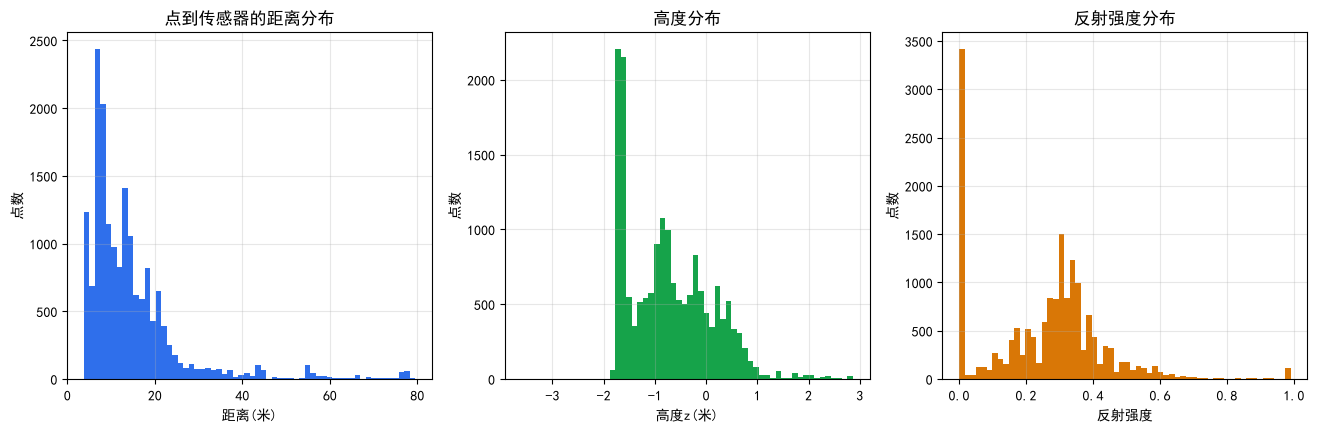

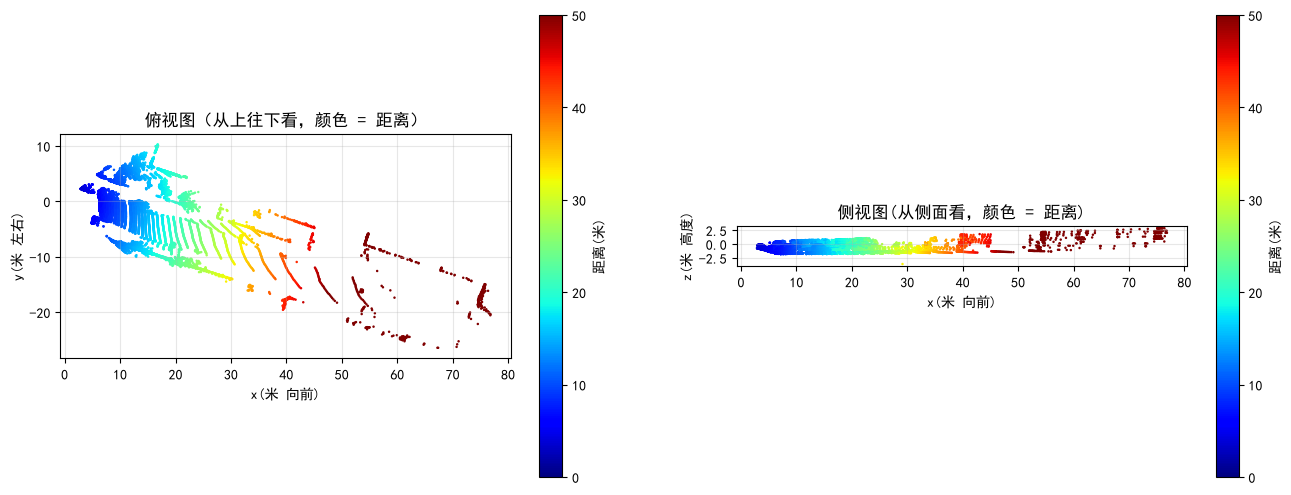

In [12]:
# 1.导入
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.sans-serif'] = ['SimHei']
rcParams['axes.unicode_minus'] = False

# 2.读文件
raw = np.fromfile('data/kitti_000008.bin',dtype=np.float32)   # numpy专门直接读取二进制文件，并且按照你指定的数据类型，把字节转成 numpy 数组
print(raw.shape)

# 3.成表格
pts = raw.reshape(-1,4)  # (x, y, z, 反射强度)
# 第二个数字 4：固定 4 列，每一行 4 个元素，对应 x,y,z,intensity
# -1：自动计算行数。numpy 自动算：总元素个数 ÷4 = 行数
print(pts.shape)

# 4.拆开看
xyz = pts[:,:3]  # 前三列x,y,z坐标
# - 第一个: ：所有行（全部点）
# - :3：从第 0 列开始，到第 3 列之前（不含 3） → 0,1,2 三列
inten = pts[:,3]  # 第四列：反射强度

print('点数：',len(pts))
print(f'x范围：{xyz[:,0].min():.2f}~{xyz[:,0].max():.2f}米')
print(f'y范围：{xyz[:,1].min():.2f}~{xyz[:,1].max():.2f}米')
print(f'z范围：{xyz[:,2].min():.2f}~{xyz[:,2].max():.2f}米')

# 5.算距离
dist = np.linalg.norm(xyz,axis=1)  # 对每一行算 √(x²+y²+z²)
# linalg = linear algebra 线性代数（numpy 里面专门做矩阵、向量运算的子模块）
# norm（范数）简单理解：范数就是向量的 “长度 / 大小”。我们现在用的默认是 2 范数（L2 范数，欧氏距离）
print(f'最远：{dist.max():.2f}米')
print(f'最近：{dist.min():.2f}米')
print(f'平均：{dist.mean():.2f}米')
print(f'中位数：{np.median(dist):.2f}米')
print(f'10米以内的点占：{(dist<10).mean() * 100 :.2f}%')
print(f'30米以外的点占：%.1f%%' % (100*(dist>30).mean()))

# 绘图
fig,axes = plt.subplots(1,3,figsize = (16,4.5))
# 图一 距离分布
axes[0].hist(dist,bins=60,color = "#2F6FEB")
# 多子图场景（fig,axes = plt.subplots()），统一全部用 axes.set_xxx
axes[0].set_title('点到传感器的距离分布') 
axes[0].set_xlabel('距离(米)')
axes[0].set_ylabel('点数')
# 图二 高度分布
axes[1].hist(xyz[:,2],bins=60,color='#16A34A')
axes[1].set_title('高度分布')
axes[1].set_xlabel('高度z(米)')
axes[1].set_ylabel('点数')
# 图三 反射强度分布
axes[2].hist(inten,bins=60,color="#D97706")
axes[2].set_title('反射强度分布')
axes[2].set_xlabel('反射强度')
axes[2].set_ylabel('点数')

for a in axes:
    a.grid(alpha = 0.3)
import os
# 如果不存在figures文件夹，则创建
if not os.path.exists("figures"):
    os.makedirs("figures")
fig.tight_layout   # 自动调整画布上所有子图、标题、坐标轴标签的位置，防止文字互相重叠挤压
fig.savefig('figures/图1_三个分布直方图.png',dpi=130,bbox_inches = 'tight')  # bbox_inches = 'tight'自动裁掉图片四周多余空白边距

# 体素降采样
def voxel_downsample(pts,voxel_size):
    # 把空间切成边长为 voxel_size 的小方块，每个方块只保留一个点
    coord = pts[:,:3]
    # 1.每个点落在哪个格子里(向下取整)
    keys = np.floor(coord/voxel_size).astype(np.int64)
    # 2.平移到0，避免负数
    keys = keys - keys.min(axis=0)
    # 3.每个方向上有多少个格子
    dims = keys.max(axis=0) + 1    #  +1:因为编号从 0 开始
    print(dims)
    # 4. 三维编号压成一个整数(方便去重)
    flat = keys[:,0]*dims[1]*dims[2] + keys[:,1]*dims[2] + keys[:,2]  # 混合进制编码
    # 5.每个格子只保留一个点
    _,first_index = np.unique(flat,return_index=True)  # flat数组和coord数组长度完全一样，一一对应
    #  return_index=True：开启这个参数后，np.unique 返回两个结果
    # 1. 第一个返回值：去重之后的不重复元素数组（这里我们暂时不用，用下划_接住扔掉）
    # 2. 第二个返回值：first_idx，每个唯一元素，在原数组中第一次出现的下标
    return first_index

for vs in [0.5,1.0,2.0,4.0]:
    out = voxel_downsample(pts,vs)
    print(f'体素{vs:.1f} -->{len(out):6d}个点，原来的{100*len(out)/len(pts):.2f}%')

# 俯视图+侧视图，把三维点云"拍扁"成两张能看懂的图
fig,axes = plt.subplots(1,2,figsize=(16,6))
# 左图：俯视图
sc = axes[0].scatter(xyz[:,0],xyz[:,1],c=dist,s=0.6,cmap='jet',vmin=0,vmax=50) # colormap颜色映射表jet：经典彩虹色，0-50限定颜色映射的数值范围
axes[0].set_title("俯视图（从上往下看，颜色 = 距离）")
axes[0].set_xlabel('x(米 向前)')
axes[0].set_ylabel('y(米 左右)')
axes[0].set_aspect('equal')    # x和y比例一致，不然形状会被拉扁
axes[0].grid(alpha=0.3)
plt.colorbar(sc,ax=axes[0],label='距离(米)')  # (颜色规则，子图，label)
# 右图：侧视图(从侧面看)
sc2 = axes[1].scatter(xyz[:,0],xyz[:,2],c=dist,s=0.6,cmap='jet',vmin=0,vmax=50)
axes[1].set_title('侧视图(从侧面看，颜色 = 距离)')
axes[1].set_xlabel('x(米 向前)')
axes[1].set_ylabel('z(米 高度)')
axes[1].set_aspect('equal')
axes[1].grid(alpha=0.3)
plt.colorbar(sc2,ax=axes[1],label='距离(米)') 
fig.tight_layout
fig.savefig('figures/图2_俯视图与侧视图.png',dpi=130,bbox_inches='tight')

# pandas做表
bins = [0,10,20,30,40,100]
labels = ['0-10米','10-20米','20-30米','30-40米','40米以上']  # bins有6个，切出 5个区间，所以labels必须写5个字符串，数量匹配
df = pd.DataFrame({'dist':dist,'z':xyz[:,2],'intensity':inten})
df['距离段'] = pd.cut(df.dist,bins=bins,labels=labels,right=False)  # right=False(保证左闭右开)
# observed=True,只返回实际存在数据的分组；就算某个区间没有任何点，也不会空行显示
tab = df.groupby(['距离段'],observed=True).agg(  
    点数=('dist','size'),
    平均强度=('intensity','mean'),
    平均高度=('z','mean')
)
tab['占比%'] = (tab.点数/len(df)*100).round(1)
print(tab.round(2))
tab.to_csv('figures/距离段统计表.csv',encoding='utf-8-sig')  # UTF-8-SIG = 带BOM的UTF-8,excel里中文不会乱码